# IsolationForest vs Proximity-Based Outlier Detection

This notebook compares two approaches to outlier detection:

1. **IsolationForest native scores** – the built-in `score_samples` / `decision_function` method, which measures how easily a point is isolated by random splits.
2. **Proximity-based outlier scores** – Breiman-style outlier detection computed from RF-GAP proximities generated by the *same* IsolationForest model.

We evaluate agreement between the two scoring methods using rank correlation, scatter plots, and detection metrics on synthetic data with known outliers.

In [361]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy import stats
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report,
)

from forestgap import with_sparse_proximity

In [362]:
from sktree import (
    ObliqueRandomForestClassifier,
    ObliqueRandomForestRegressor,
    PatchObliqueRandomForestClassifier,
    PatchObliqueRandomForestRegressor,
    ExtraObliqueRandomForestClassifier,
    ExtraObliqueRandomForestRegressor,
    HonestForestClassifier,
    UnsupervisedRandomForest,
    ExtendedIsolationForest,
)

## 1  Synthetic dataset

We generate clustered inliers plus uniformly scattered outliers so ground truth is known.

In [363]:
RANDOM_STATE = 42
CONTAMINATION = 0.01
N_SAMPLES = 5000

rng = np.random.RandomState(RANDOM_STATE)

n_inliers = int(N_SAMPLES * (1 - CONTAMINATION))
n_outliers = N_SAMPLES - n_inliers

X_in, _ = make_blobs(
    n_samples=n_inliers, n_features=2, centers=2,
    cluster_std=0.8, random_state=RANDOM_STATE,
)

# Outliers drawn uniformly from the bounding box + margin
lo = X_in.min(axis=0) - 4
hi = X_in.max(axis=0) + 4
X_out = rng.uniform(lo, hi, size=(n_outliers, X_in.shape[1]))

X = np.vstack([X_in, X_out])
y_true = np.concatenate([np.zeros(n_inliers, dtype=int),
                          np.ones(n_outliers, dtype=int)])

scaler = StandardScaler()
X = scaler.fit_transform(X)

print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Inliers: {n_inliers}, Outliers: {n_outliers}")

Dataset: 5000 samples, 2 features
Inliers: 4950, Outliers: 50


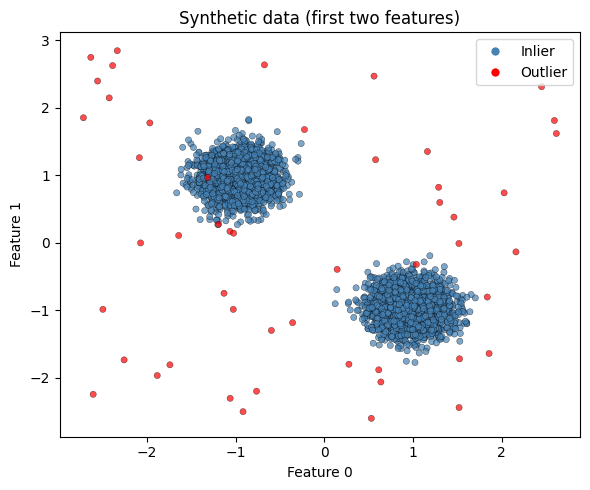

In [364]:
fig, ax = plt.subplots(figsize=(6, 5))
colors = ['steelblue' if lbl == 0 else 'red' for lbl in y_true]
ax.scatter(X[:, 0], X[:, 1], c=colors, s=20, alpha=0.7, edgecolors='k', linewidths=0.3)
ax.set_xlabel('Feature 0')
ax.set_ylabel('Feature 1')
ax.set_title('Synthetic data (first two features)')
from matplotlib.lines import Line2D
legend_elems = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='steelblue', markersize=7, label='Inlier'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=7, label='Outlier'),
]
ax.legend(handles=legend_elems)
plt.tight_layout()
plt.show()

## 2  Fit IsolationForest with RF-GAP proximities

In [365]:
ProxIsoForest = with_sparse_proximity(ExtendedIsolationForest)

model = ProxIsoForest(
    n_estimators=200,
    contamination=CONTAMINATION,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    prox_method='oob',
    max_features = 2 # Needed for ExtendedIsolationForest
)
model.fit(X)
print('Model fitted.')

Model fitted.


## 3  Compute both outlier scores

- **IsolationForest score**: `score_samples(X)` (more negative = more anomalous). We negate it so that *higher = more outlier-like*, matching the proximity convention.
- **Proximity-based score**: `outlier_scores()` with no labels — the unsupervised (label-free) path computes `sum_k prox(n,k)^2` over *all* samples, then MAD-standardises globally. No class labels needed.

In [366]:
# IsolationForest native anomaly score (negated so higher = more anomalous)
iso_scores = -model.score_samples(X)

# Proximity-based outlier score (label-free: y=None uses global proximities)
prox_scores = model.outlier_scores()

print(f"IsolationForest scores – min: {iso_scores.min():.4f}, max: {iso_scores.max():.4f}")
print(f"Proximity scores       – min: {prox_scores.min():.4f}, max: {prox_scores.max():.4f}")

IsolationForest scores – min: 0.4118, max: 0.7696
Proximity scores       – min: 0.0000, max: 72.3162


## 4  Score distributions

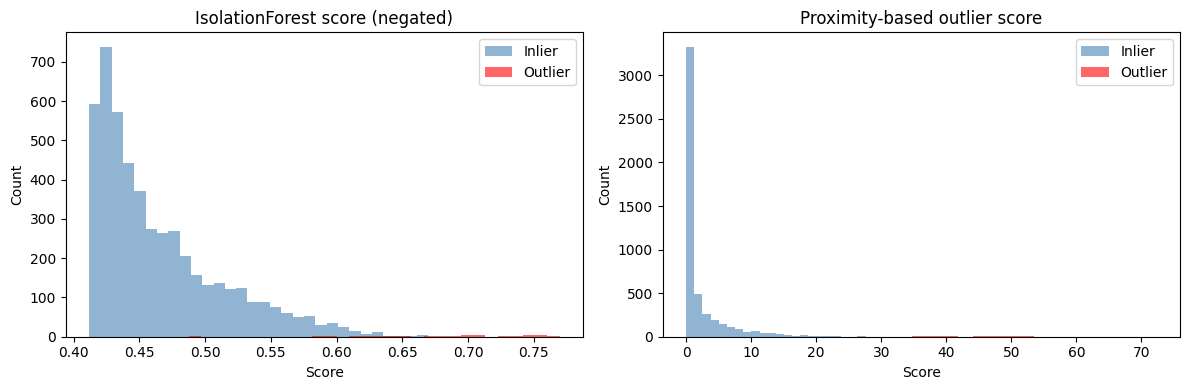

In [367]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, scores, title in zip(
    axes,
    [iso_scores, prox_scores],
    ['IsolationForest score (negated)', 'Proximity-based outlier score'],
):
    ax.hist(scores[y_true == 0], bins=30, alpha=0.6, label='Inlier', color='steelblue')
    ax.hist(scores[y_true == 1], bins=30, alpha=0.6, label='Outlier', color='red')
    ax.set_xlabel('Score')
    ax.set_ylabel('Count')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

## 5  Rank correlation between scores

In [368]:
spearman_r, spearman_p = stats.spearmanr(iso_scores, prox_scores)
kendall_tau, kendall_p = stats.kendalltau(iso_scores, prox_scores)
pearson_r, pearson_p = stats.pearsonr(iso_scores, prox_scores)

print(f"Spearman rho = {spearman_r:.4f}  (p = {spearman_p:.2e})")
print(f"Kendall  tau = {kendall_tau:.4f}  (p = {kendall_p:.2e})")
print(f"Pearson  r   = {pearson_r:.4f}  (p = {pearson_p:.2e})")

Spearman rho = 0.5175  (p = 0.00e+00)
Kendall  tau = 0.3034  (p = 4.19e-227)
Pearson  r   = 0.8249  (p = 0.00e+00)


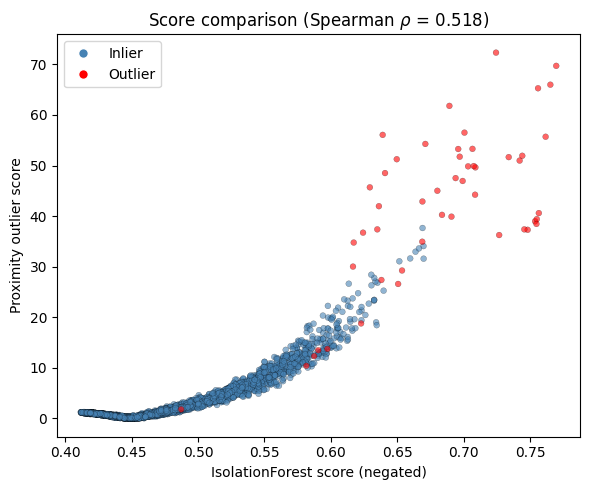

In [369]:
fig, ax = plt.subplots(figsize=(6, 5))
colors = np.where(y_true == 1, 'red', 'steelblue')
ax.scatter(iso_scores, prox_scores, c=colors, s=18, alpha=0.6, edgecolors='k', linewidths=0.2)
ax.set_xlabel('IsolationForest score (negated)')
ax.set_ylabel('Proximity outlier score')
ax.set_title(f'Score comparison (Spearman $\\rho$ = {spearman_r:.3f})')

from matplotlib.lines import Line2D
legend_elems = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='steelblue', markersize=7, label='Inlier'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=7, label='Outlier'),
]
ax.legend(handles=legend_elems)
plt.tight_layout()
plt.show()

## 6  ROC & Precision-Recall curves

Both scores are evaluated against the known ground-truth labels.

In [370]:
iso_auc = roc_auc_score(y_true, iso_scores)
prox_auc = roc_auc_score(y_true, prox_scores)
iso_ap = average_precision_score(y_true, iso_scores)
prox_ap = average_precision_score(y_true, prox_scores)

print(f"{'Method':<30} {'ROC-AUC':>10} {'Avg Precision':>15}")
print('-' * 57)
print(f"{'IsolationForest (native)':<30} {iso_auc:>10.4f} {iso_ap:>15.4f}")
print(f"{'Proximity-based':<30} {prox_auc:>10.4f} {prox_ap:>15.4f}")

Method                            ROC-AUC   Avg Precision
---------------------------------------------------------
IsolationForest (native)           0.9924          0.8598
Proximity-based                    0.9914          0.8915


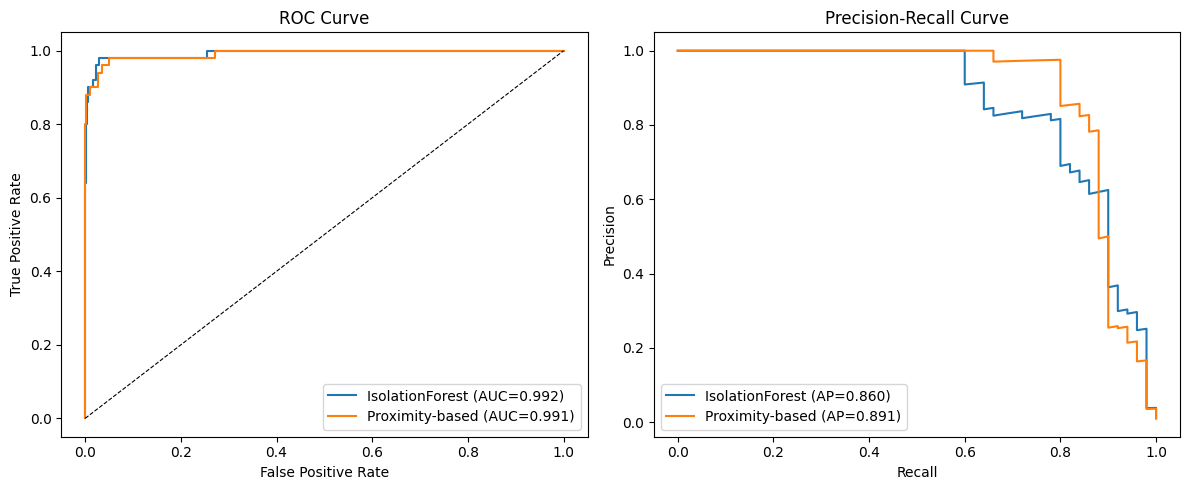

In [371]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curves
ax = axes[0]
for scores, label, auc_val in [
    (iso_scores, 'IsolationForest', iso_auc),
    (prox_scores, 'Proximity-based', prox_auc),
]:
    fpr, tpr, _ = roc_curve(y_true, scores)
    ax.plot(fpr, tpr, label=f'{label} (AUC={auc_val:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend()

# Precision-Recall curves
ax = axes[1]
for scores, label, ap_val in [
    (iso_scores, 'IsolationForest', iso_ap),
    (prox_scores, 'Proximity-based', prox_ap),
]:
    prec, rec, _ = precision_recall_curve(y_true, scores)
    ax.plot(rec, prec, label=f'{label} (AP={ap_val:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend()

plt.tight_layout()
plt.show()

## 7  Feature-space visualisation coloured by each score

Side-by-side scatter plots in the first two features, coloured by each method's score.

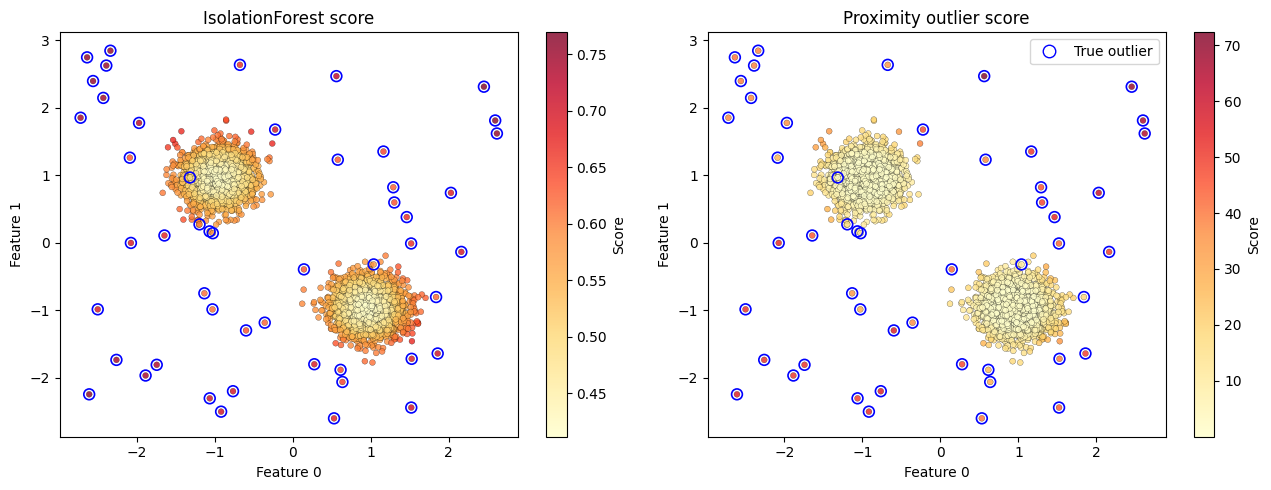

In [372]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, scores, title in zip(
    axes,
    [iso_scores, prox_scores],
    ['IsolationForest score', 'Proximity outlier score'],
):
    sc = ax.scatter(
        X[:, 0], X[:, 1], c=scores, cmap='YlOrRd', s=18, alpha=0.8,
        edgecolors='k', linewidths=0.2,
    )
    fig.colorbar(sc, ax=ax, label='Score')
    # Ring the true outliers
    outlier_mask = y_true == 1
    ax.scatter(
        X[outlier_mask, 0], X[outlier_mask, 1],
        facecolors='none', edgecolors='blue', linewidths=1.2, s=60,
    )
    ax.set_xlabel('Feature 0')
    ax.set_ylabel('Feature 1')
    ax.set_title(title)

# Common legend for the blue rings
from matplotlib.lines import Line2D
legend_elem = Line2D(
    [0], [0], marker='o', color='w', markerfacecolor='none',
    markeredgecolor='blue', markersize=9, linewidth=0, label='True outlier',
)
axes[1].legend(handles=[legend_elem], loc='upper right')

plt.tight_layout()
plt.show()

## 8  Rank agreement at the top

How many of each method's top-k flagged points are actually true outliers?

In [373]:
k_values = [10, 20, 30, 50, n_outliers]

iso_order = np.argsort(iso_scores)[::-1]
prox_order = np.argsort(prox_scores)[::-1]

rows = []
for k in k_values:
    iso_topk = set(iso_order[:k])
    prox_topk = set(prox_order[:k])
    overlap = len(iso_topk & prox_topk)
    iso_true = y_true[iso_order[:k]].sum()
    prox_true = y_true[prox_order[:k]].sum()
    rows.append({
        'k': k,
        'overlap': overlap,
        'iso_true_outliers': int(iso_true),
        'prox_true_outliers': int(prox_true),
        'iso_precision@k': iso_true / k,
        'prox_precision@k': prox_true / k,
    })

pd.DataFrame(rows).set_index('k')

,overlap,iso_true_outliers,prox_true_outliers,iso_precision@k,prox_precision@k
k,,,,,
10,4,10,10,1.0,1.00
20,12,20,20,1.0,1.00
30,24,30,30,1.0,1.00
50,45,40,42,0.8,0.84
50,45,40,42,0.8,0.84


## 9  Binary detection comparison

Using IsolationForest's built-in `predict` threshold and, for the proximity method, the same contamination rate to flag the top-scoring points.

In [374]:
# IsolationForest binary predictions
iso_pred = (model.predict(X) == -1).astype(int)

# Proximity-based: flag top-contamination fraction
threshold_idx = int(np.ceil(CONTAMINATION * len(prox_scores)))
prox_threshold = np.sort(prox_scores)[::-1][threshold_idx - 1]
prox_pred = (prox_scores >= prox_threshold).astype(int)

print('=== IsolationForest (native threshold) ===')
print(classification_report(y_true, iso_pred, target_names=['Inlier', 'Outlier']))

print('=== Proximity-based (top-contamination threshold) ===')
print(classification_report(y_true, prox_pred, target_names=['Inlier', 'Outlier']))

=== IsolationForest (native threshold) ===
              precision    recall  f1-score   support

      Inlier       1.00      1.00      1.00      4950
     Outlier       0.80      0.80      0.80        50

    accuracy                           1.00      5000
   macro avg       0.90      0.90      0.90      5000
weighted avg       1.00      1.00      1.00      5000

=== Proximity-based (top-contamination threshold) ===
              precision    recall  f1-score   support

      Inlier       1.00      1.00      1.00      4950
     Outlier       0.84      0.84      0.84        50

    accuracy                           1.00      5000
   macro avg       0.92      0.92      0.92      5000
weighted avg       1.00      1.00      1.00      5000



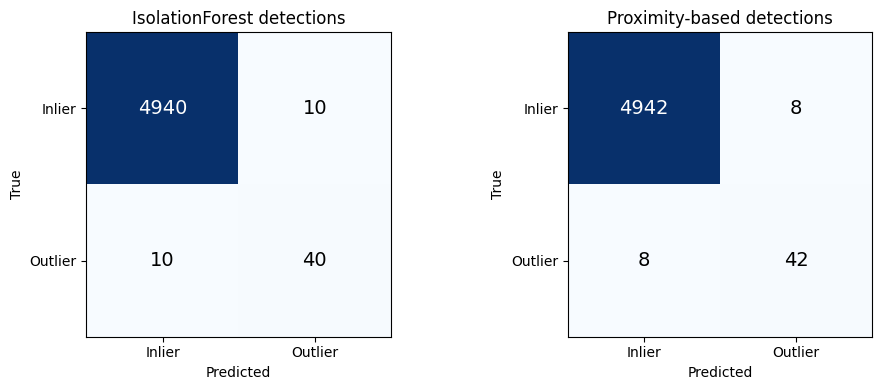

In [375]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pred, title in zip(
    axes,
    [iso_pred, prox_pred],
    ['IsolationForest detections', 'Proximity-based detections'],
):
    cm = confusion_matrix(y_true, pred)
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Inlier', 'Outlier'])
    ax.set_yticklabels(['Inlier', 'Outlier'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)

plt.tight_layout()
plt.show()

## 10  Score-rank comparison plot

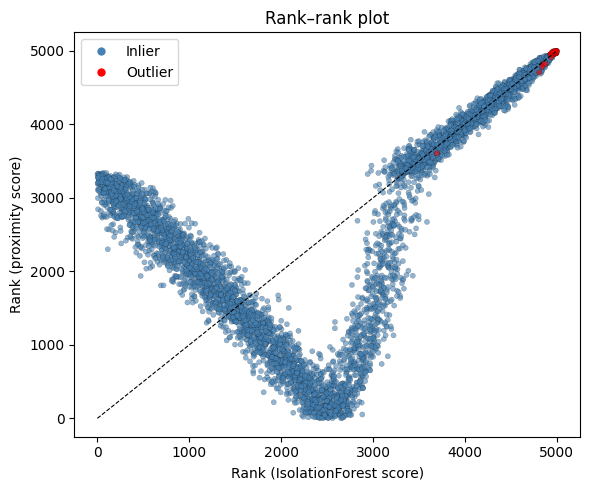

In [376]:
iso_ranks = stats.rankdata(iso_scores)
prox_ranks = stats.rankdata(prox_scores)

fig, ax = plt.subplots(figsize=(6, 5))
colors = np.where(y_true == 1, 'red', 'steelblue')
ax.scatter(iso_ranks, prox_ranks, c=colors, s=14, alpha=0.6, edgecolors='k', linewidths=0.15)
lims = [0, len(iso_ranks) + 1]
ax.plot(lims, lims, 'k--', lw=0.8)
ax.set_xlabel('Rank (IsolationForest score)')
ax.set_ylabel('Rank (proximity score)')
ax.set_title('Rank–rank plot')

from matplotlib.lines import Line2D
legend_elems = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='steelblue', markersize=7, label='Inlier'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=7, label='Outlier'),
]
ax.legend(handles=legend_elems)
plt.tight_layout()
plt.show()

## 11  Disagreement analysis

The ground-truth "outliers" were drawn *uniformly* over a wide bounding box, so some inevitably land inside a cluster. These **impostor outliers** are structurally indistinguishable from inliers — no method should detect them. Meanwhile, some true *inliers* sit at cluster peripheries where proximity connections are weak; the proximity method may flag these even though IsolationForest does not.

We classify every point into four quadrants based on whether each method's score exceeds its contamination-rate threshold:

| Quadrant | IsoForest | Proximity | Interpretation |
|----------|-----------|-----------|----------------|
| **Both flag** | high | high | Consensus anomalies |
| **Iso only** | high | low | Isolation-easy but proximity-connected |
| **Prox only** | low | high | Well-enclosed but proximity-isolated |
| **Neither** | low | low | Consensus normals |

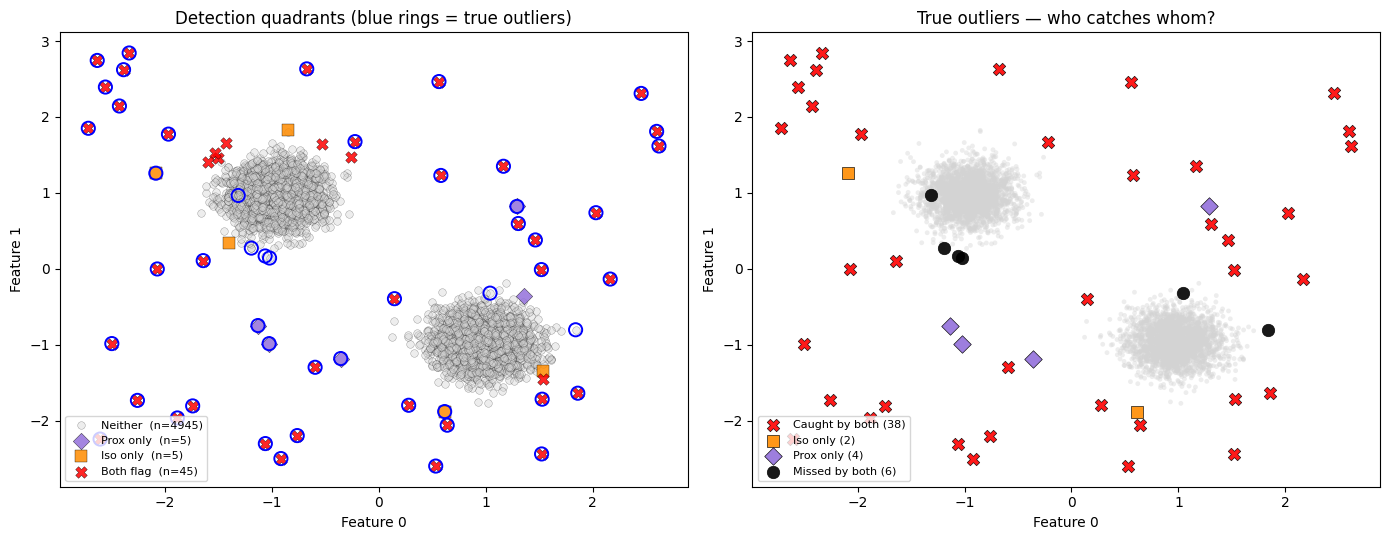


True-outlier breakdown (n=50):
  Caught by both methods: 38
  Iso only:               2
  Prox only:              4
  Missed by both:         6

False-positive breakdown (flagged inliers):
  IsolationForest FP: 10
  Proximity FP:       8


In [377]:
# Assign each point to a quadrant
quadrant = np.empty(len(y_true), dtype='U12')
quadrant[(iso_pred == 1) & (prox_pred == 1)] = 'Both flag'
quadrant[(iso_pred == 1) & (prox_pred == 0)] = 'Iso only'
quadrant[(iso_pred == 0) & (prox_pred == 1)] = 'Prox only'
quadrant[(iso_pred == 0) & (prox_pred == 0)] = 'Neither'

quad_colors = {
    'Both flag': 'red',
    'Iso only':  'darkorange',
    'Prox only': 'mediumpurple',
    'Neither':   'lightgrey',
}
quad_markers = {
    'Both flag': 'X',
    'Iso only':  's',
    'Prox only': 'D',
    'Neither':   'o',
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Left panel: quadrant membership in feature space ---
ax = axes[0]
for q in ['Neither', 'Prox only', 'Iso only', 'Both flag']:
    mask = quadrant == q
    ax.scatter(
        X[mask, 0], X[mask, 1],
        c=quad_colors[q], marker=quad_markers[q],
        s=30 if q == 'Neither' else 70,
        alpha=0.4 if q == 'Neither' else 0.85,
        edgecolors='k', linewidths=0.3,
        label=f'{q}  (n={mask.sum()})',
    )
# Ring true outliers regardless of quadrant
ax.scatter(
    X[y_true == 1, 0], X[y_true == 1, 1],
    facecolors='none', edgecolors='blue', linewidths=1.4, s=90,
)
ax.set_xlabel('Feature 0'); ax.set_ylabel('Feature 1')
ax.set_title('Detection quadrants (blue rings = true outliers)')
ax.legend(fontsize=8, loc='lower left')

# --- Right panel: which true outliers each method misses ---
ax = axes[1]
# True outliers that fell inside clusters ("impostors")
missed_both = (y_true == 1) & (iso_pred == 0) & (prox_pred == 0)
missed_iso  = (y_true == 1) & (iso_pred == 0) & (prox_pred == 1)
missed_prox = (y_true == 1) & (iso_pred == 1) & (prox_pred == 0)
caught_both = (y_true == 1) & (iso_pred == 1) & (prox_pred == 1)

# Background: all inliers in light grey
ax.scatter(X[y_true == 0, 0], X[y_true == 0, 1],
           c='lightgrey', s=12, alpha=0.4, edgecolors='none')

for mask, color, marker, label in [
    (caught_both, 'red',          'X', f'Caught by both ({caught_both.sum()})'),
    (missed_prox, 'darkorange',   's', f'Iso only ({missed_prox.sum()})'),
    (missed_iso,  'mediumpurple', 'D', f'Prox only ({missed_iso.sum()})'),
    (missed_both, 'black',        'o', f'Missed by both ({missed_both.sum()})'),
]:
    if mask.sum() == 0:
        continue
    ax.scatter(X[mask, 0], X[mask, 1],
               c=color, marker=marker, s=80, alpha=0.9,
               edgecolors='k', linewidths=0.5, label=label)

ax.set_xlabel('Feature 0'); ax.set_ylabel('Feature 1')
ax.set_title('True outliers — who catches whom?')
ax.legend(fontsize=8, loc='lower left')

plt.tight_layout()
plt.show()

# Print a summary table
print(f"\nTrue-outlier breakdown (n={n_outliers}):")
print(f"  Caught by both methods: {caught_both.sum()}")
print(f"  Iso only:               {missed_prox.sum()}")
print(f"  Prox only:              {missed_iso.sum()}")
print(f"  Missed by both:         {missed_both.sum()}")
print(f"\nFalse-positive breakdown (flagged inliers):")
fp_iso  = ((iso_pred == 1) & (y_true == 0)).sum()
fp_prox = ((prox_pred == 1) & (y_true == 0)).sum()
print(f"  IsolationForest FP: {fp_iso}")
print(f"  Proximity FP:       {fp_prox}")

### Impostor outliers and structural edge-cases

**Why IsolationForest appears to "overfit":** It doesn't — the ground-truth labels are noisy. Because outliers were sampled *uniformly*, some land squarely inside dense clusters. These impostors are **structurally inliers** regardless of their label. Any method that flags them is arguably making an error, not a correct detection.

**Why the proximity method flags some inliers:** Points at cluster boundaries have fewer co-landing neighbours in the forest's leaf space, so their $\sum_k P(n,k)^2$ is small — yielding a high outlier score. These are genuine *structural* outliers even though they were generated from the inlier distribution. IsolationForest's path-length criterion is less sensitive to this because a point inside (even at the edge of) a dense region still requires many splits to isolate.

The plot below separates true outliers by their distance to the nearest inlier cluster centre, showing that both methods miss the impostors closest to cluster cores.

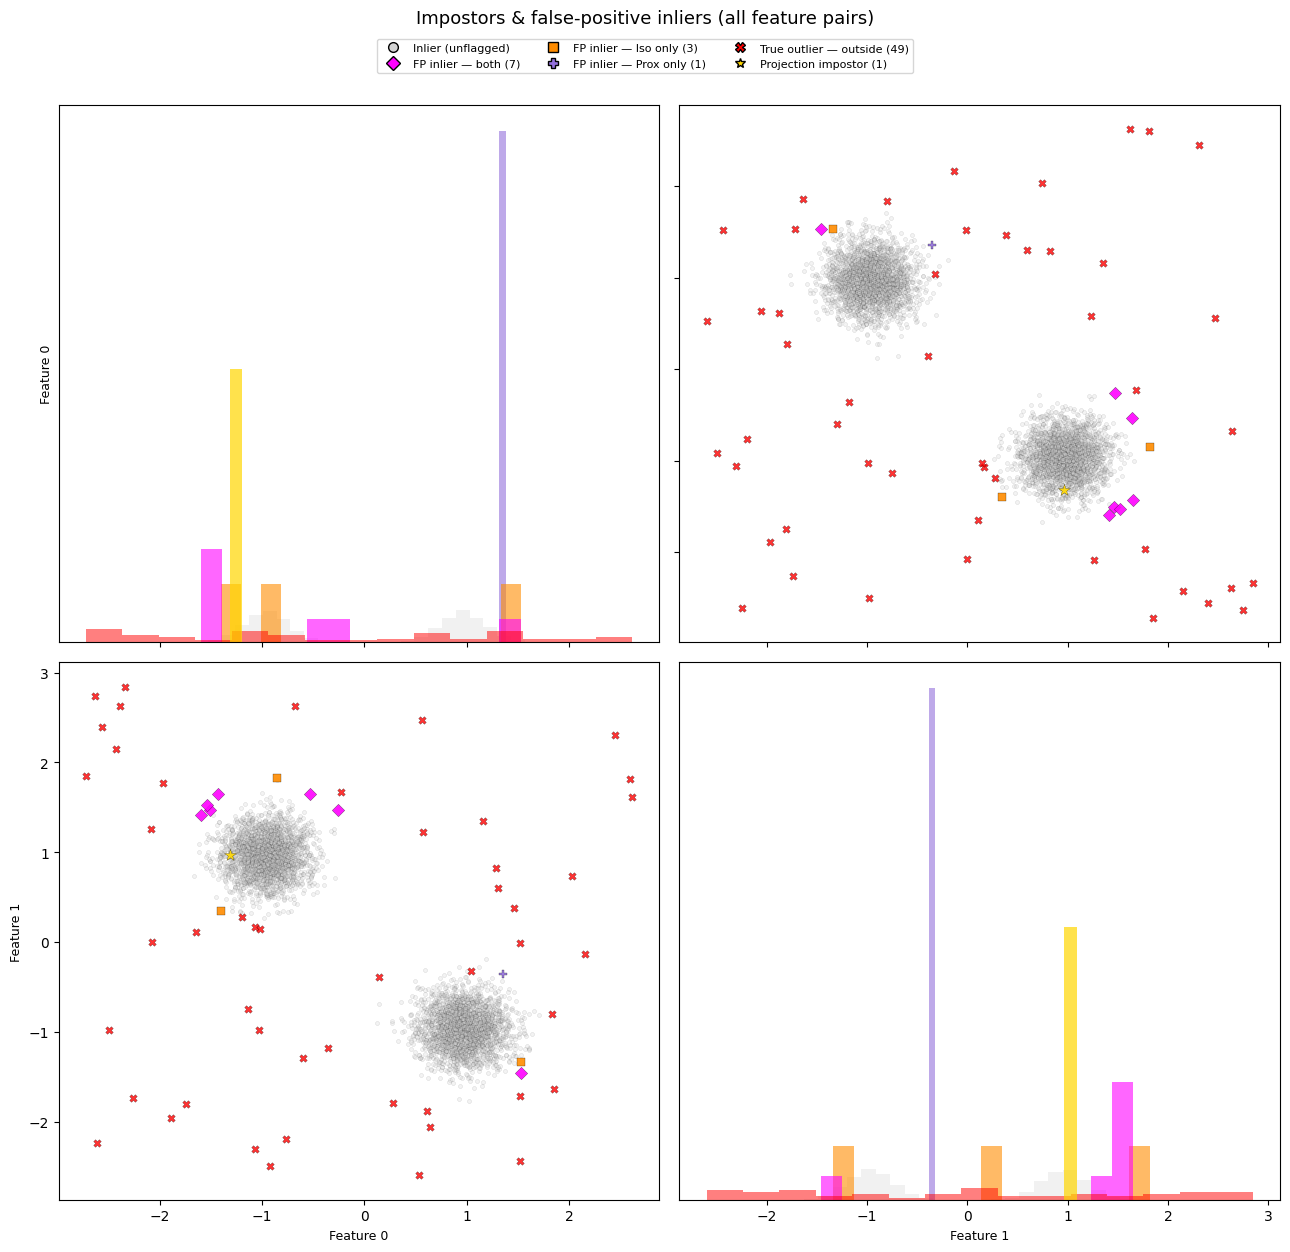


Impostor analysis:
  4D impostors (within 95th %ile in full space):       1 / 50
  2D projection impostors (inside cluster in ≥1 pair): 1 / 50
    Flagged by IsolationForest: 0
    Flagged by Proximity:       0

False-positive inliers (true inliers flagged as outliers):
  Flagged by both methods:         7
  Flagged by IsolationForest only: 3
  Flagged by Proximity only:       1

Projection impostors appear inside clusters in some 2D views but are
separable in the full 4D space — explaining why IsolationForest detects them.


In [378]:
from sklearn.cluster import KMeans
from itertools import combinations

n_feat = X.shape[1]

# --- 4D impostor analysis (full feature space) ---
km = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(X[y_true == 0])
centers = km.cluster_centers_

outlier_X = X[y_true == 1]
dists_4d = np.min(np.linalg.norm(outlier_X[:, None, :] - centers[None, :, :], axis=2), axis=1)

inlier_dists_4d = np.min(
    np.linalg.norm(X[y_true == 0][:, None, :] - centers[None, :, :], axis=2), axis=1
)
inlier_radius_4d = np.percentile(inlier_dists_4d, 95)
is_impostor_4d = dists_4d <= inlier_radius_4d

# --- 2D impostor analysis (per feature-pair projection) ---
# An outlier is a "projection impostor" if it falls within the 95th-percentile
# inlier radius in *any* 2D projection.  We store which pairs it's inside.
pair_list = list(combinations(range(n_feat), 2))
is_impostor_2d = np.zeros(len(outlier_X), dtype=bool)

for fi, fj in pair_list:
    X_pair = X[:, [fi, fj]]
    km_pair = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(X_pair[y_true == 0])
    c_pair = km_pair.cluster_centers_
    inlier_d = np.min(np.linalg.norm(X_pair[y_true == 0][:, None, :] - c_pair[None, :, :], axis=2), axis=1)
    r95 = np.percentile(inlier_d, 95)
    out_d = np.min(np.linalg.norm(outlier_X[:, [fi, fj]][:, None, :] - c_pair[None, :, :], axis=2), axis=1)
    is_impostor_2d |= (out_d <= r95)

# Combined: impostor in at least one 2D projection
is_impostor = is_impostor_2d  # use the broader definition for the pairs plot

# False-positive inliers: true inliers flagged by either method
fp_iso_mask  = (y_true == 0) & (iso_pred == 1)
fp_prox_mask = (y_true == 0) & (prox_pred == 1)
fp_both_mask = fp_iso_mask & fp_prox_mask
fp_iso_only  = fp_iso_mask & ~fp_prox_mask
fp_prox_only = fp_prox_mask & ~fp_iso_mask

# True outliers
outlier_idx = np.where(y_true == 1)[0]
impostor_idx = outlier_idx[is_impostor]
outside_idx = outlier_idx[~is_impostor]

# Unflagged inliers
unflagged_inlier = (y_true == 0) & (iso_pred == 0) & (prox_pred == 0)

# Build category arrays for plotting
cat_order = []
cat_order.append((unflagged_inlier, 'lightgrey', 'o', 8, 0.25, 'Inlier (unflagged)'))
if fp_both_mask.sum() > 0:
    cat_order.append((fp_both_mask, 'magenta', 'D', 40, 0.9, f'FP inlier — both ({fp_both_mask.sum()})'))
if fp_iso_only.sum() > 0:
    cat_order.append((fp_iso_only, 'darkorange', 's', 35, 0.9, f'FP inlier — Iso only ({fp_iso_only.sum()})'))
if fp_prox_only.sum() > 0:
    cat_order.append((fp_prox_only, 'mediumpurple', 'P', 40, 0.9, f'FP inlier — Prox only ({fp_prox_only.sum()})'))

outside_mask = np.zeros(len(y_true), dtype=bool)
outside_mask[outside_idx] = True
impostor_mask = np.zeros(len(y_true), dtype=bool)
impostor_mask[impostor_idx] = True

cat_order.append((outside_mask, 'red', 'X', 30, 0.8, f'True outlier — outside ({len(outside_idx)})'))
cat_order.append((impostor_mask, 'gold', '*', 80, 0.9, f'Projection impostor ({len(impostor_idx)})'))

# --- Pairs plot ---
feat_labels = [f'Feature {i}' for i in range(n_feat)]

fig, axes = plt.subplots(n_feat, n_feat, figsize=(13, 12))

for i in range(n_feat):
    for j in range(n_feat):
        ax = axes[i, j]
        if i == j:
            ax.hist(X[unflagged_inlier, i], bins=25, alpha=0.3, color='lightgrey', density=True)
            if fp_prox_only.sum() > 0:
                ax.hist(X[fp_prox_only, i], bins=15, alpha=0.6, color='mediumpurple', density=True)
            if fp_iso_only.sum() > 0:
                ax.hist(X[fp_iso_only, i], bins=15, alpha=0.6, color='darkorange', density=True)
            if fp_both_mask.sum() > 0:
                ax.hist(X[fp_both_mask, i], bins=15, alpha=0.6, color='magenta', density=True)
            if outside_mask.sum() > 0:
                ax.hist(X[outside_mask, i], bins=15, alpha=0.5, color='red', density=True)
            if impostor_mask.sum() > 0:
                ax.hist(X[impostor_mask, i], bins=8, alpha=0.7, color='gold', density=True)
            ax.set_yticks([])
        else:
            for mask, color, marker, size, alpha, _ in cat_order:
                if mask.sum() == 0:
                    continue
                ax.scatter(X[mask, j], X[mask, i], c=color, marker=marker,
                           s=size, alpha=alpha, edgecolors='k', linewidths=0.2)

        if i == n_feat - 1:
            ax.set_xlabel(feat_labels[j], fontsize=9)
        else:
            ax.set_xticklabels([])
        if j == 0:
            ax.set_ylabel(feat_labels[i], fontsize=9)
        else:
            ax.set_yticklabels([])

from matplotlib.lines import Line2D
handles = []
for mask, color, marker, size, alpha, label in cat_order:
    handles.append(Line2D([0], [0], marker=marker, color='w', markerfacecolor=color,
                          markeredgecolor='k', markersize=7, linewidth=0, label=label))
fig.legend(handles=handles, loc='upper center', ncol=3, fontsize=8,
           frameon=True, bbox_to_anchor=(0.5, 1.02))

fig.suptitle('Impostors & false-positive inliers (all feature pairs)', fontsize=13, y=1.04)
plt.tight_layout()
plt.show()

# --- Summary ---
n_imp_2d = is_impostor_2d.sum()
n_imp_4d = is_impostor_4d.sum()
imp_2d_global = outlier_idx[is_impostor_2d]

print(f"\nImpostor analysis:")
print(f"  4D impostors (within 95th %ile in full space):       {n_imp_4d} / {n_outliers}")
print(f"  2D projection impostors (inside cluster in ≥1 pair): {n_imp_2d} / {n_outliers}")
if n_imp_2d > 0:
    print(f"    Flagged by IsolationForest: {iso_pred[imp_2d_global].sum()}")
    print(f"    Flagged by Proximity:       {prox_pred[imp_2d_global].sum()}")

print(f"\nFalse-positive inliers (true inliers flagged as outliers):")
print(f"  Flagged by both methods:         {fp_both_mask.sum()}")
print(f"  Flagged by IsolationForest only: {fp_iso_only.sum()}")
print(f"  Flagged by Proximity only:       {fp_prox_only.sum()}")

print(f"\nProjection impostors appear inside clusters in some 2D views but are")
print("separable in the full 4D space — explaining why IsolationForest detects them.")

In [379]:
# Inspect FP inliers: where do they sit relative to cluster centres?
fp_prox_idx = np.where(fp_prox_only)[0]

if len(fp_prox_idx) > 0:
    # Distance to nearest cluster centre (full feature space)
    fp_dists = np.min(
        np.linalg.norm(X[fp_prox_idx][:, None, :] - centers[None, :, :], axis=2), axis=1
    )

    # Percentile of each FP inlier's distance within the inlier distance distribution
    fp_pctiles = np.array([
        (inlier_dists_4d <= d).mean() * 100 for d in fp_dists
    ])

    df_fp = pd.DataFrame({
        'index': fp_prox_idx,
        'dist_to_nearest_centre': fp_dists,
        'pctile_among_inliers': fp_pctiles,
        'prox_score': prox_scores[fp_prox_idx],
        'iso_score': iso_scores[fp_prox_idx],
        **{f'feat_{i}': X[fp_prox_idx, i] for i in range(n_feat)},
    }).sort_values('dist_to_nearest_centre', ascending=False)

    print("FP inliers flagged by Proximity only")
    print(f"  Inlier 95th-pctile radius = {inlier_radius_4d:.3f}\n")

    print(df_fp.to_string(index=False, float_format='%.3f'))   
    print("No FP inliers flagged by Proximity only.")

else:    
    fp_pctiles = np.array([])
    fp_dists = np.array([])

FP inliers flagged by Proximity only
  Inlier 95th-pctile radius = 0.499

 index  dist_to_nearest_centre  pctile_among_inliers  prox_score  iso_score  feat_0  feat_1
  3997                   0.737                99.778      28.409      0.630   1.354  -0.353
No FP inliers flagged by Proximity only.


In [380]:
# Diagnose WHY low-percentile FP inliers have high proximity outlier scores.
# Examine their proximity row structure vs typical inliers.

P = model.get_proximities()  # sparse proximity matrix

# Cluster label for each sample (from the KMeans)
cluster_labels = km.predict(X)

if len(fp_prox_idx) > 0:
    # For each FP inlier, compute proximity diagnostics
    diag_rows = []
    for idx in fp_prox_idx:
        row = P[idx]
        row_sq = row.multiply(row)
        nnz = row.nnz
        sum_p = row.sum()
        sum_p2 = row_sq.sum()
        max_p = row.max()

        nz_cols = row.nonzero()[1]
        own_cluster = cluster_labels[idx]
        nbr_clusters = cluster_labels[nz_cols]
        frac_same = (nbr_clusters == own_cluster).mean() if len(nbr_clusters) > 0 else 0

        diag_rows.append({
            'index': idx,
            'cluster': own_cluster,
            'nnz_neighbours': nnz,
            'sum_prox': sum_p,
            'sum_prox_sq': sum_p2,
            'max_prox': max_p,
            'frac_same_cluster': frac_same,
            'pctile': fp_pctiles[fp_prox_idx == idx][0],
        })

    df_diag = pd.DataFrame(diag_rows).sort_values('pctile')

    print("=== FP inlier proximity diagnostics (sorted by distance percentile) ===\n")
    print(df_diag.to_string(index=False, float_format='%.4f'))
else:
    print("No FP inliers flagged by Proximity only — nothing to diagnose.")

# Compute the same stats for a random sample of unflagged inliers for comparison
rng_diag = np.random.RandomState(0)
ref_idx = rng_diag.choice(np.where(unflagged_inlier)[0], size=50, replace=False)
ref_rows = []
for idx in ref_idx:
    row = P[idx]
    row_sq = row.multiply(row)
    nz_cols = row.nonzero()[1]
    own_cluster = cluster_labels[idx]
    nbr_clusters = cluster_labels[nz_cols]
    ref_rows.append({
        'nnz_neighbours': row.nnz,
        'sum_prox': row.sum(),
        'sum_prox_sq': row_sq.sum(),
        'max_prox': row.max(),
        'frac_same_cluster': (nbr_clusters == own_cluster).mean() if len(nbr_clusters) > 0 else 0,
    })
df_ref = pd.DataFrame(ref_rows)

print(f"\n=== Typical unflagged inlier (median of 50 random samples) ===")
print(df_ref.median().to_string(float_format='%.4f'))
print(f"\n--- Interpretation ---")

print("• sum_prox_sq drives the outlier score: lower → higher outlier score")
print("• frac_same_cluster: fraction of proximity neighbours in the same KMeans cluster")
print("  Low values mean the forest's splits scatter this point across clusters")

=== FP inlier proximity diagnostics (sorted by distance percentile) ===

 index  cluster  nnz_neighbours  sum_prox  sum_prox_sq  max_prox  frac_same_cluster  pctile
  3997        2            1833   66.8381      12.2074    1.0000             0.4741 99.7778

=== Typical unflagged inlier (median of 50 random samples) ===
nnz_neighbours      2483.0000
sum_prox             421.2523
sum_prox_sq          128.0587
max_prox               1.0000
frac_same_cluster      0.5059

--- Interpretation ---
• sum_prox_sq drives the outlier score: lower → higher outlier score
• frac_same_cluster: fraction of proximity neighbours in the same KMeans cluster
  Low values mean the forest's splits scatter this point across clusters


C:\Users\rhodes8\AppData\Local\Temp\ipykernel_25504\1641284974.py:48: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_cluster, labels=[f'Cl {cl}\n(n={cluster_sizes[cl]})' for cl in sorted(cluster_sizes.index)],


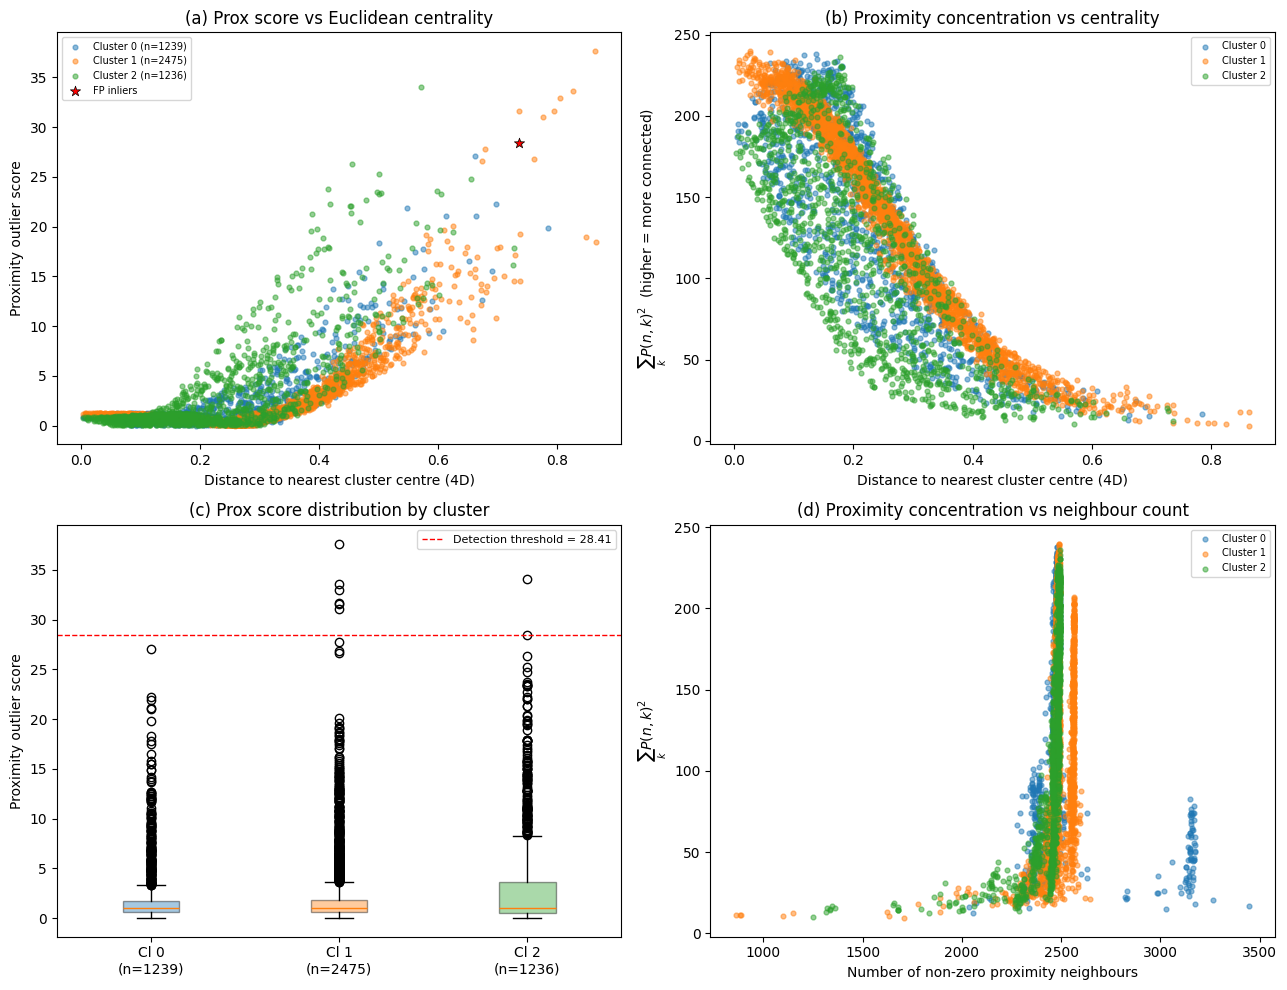


Per-cluster inlier proximity summary:
 Cluster   Size   Median score    Mean sum_p²   Median nnz  Flagged
       0   1239          0.959      135.56651         2475        0
       1   2475          0.997      133.33711         2485        0
       2   1236          1.030      117.45818         2476        1

→ Smaller clusters have lower sum_prox_sq because each point has fewer
  same-cluster neighbours in the forest's leaf space. IsolationForest
  also tends to isolate small-cluster points faster, creating shallower
  leaves with less consistent co-landing — further diluting proximities.


In [381]:
# Why do central inliers get high proximity outlier scores?
# Examine the relationship between distance-to-center and proximity score for ALL inliers.

inlier_mask = y_true == 0
inlier_dist_to_center = inlier_dists_4d  # already computed: nearest cluster centre in 4D
inlier_prox_scores = prox_scores[inlier_mask]
inlier_iso_scores = iso_scores[inlier_mask]

# Compute sum_prox_sq for every inlier (this drives the outlier score)
inlier_sum_p2 = np.array([
    P[i].multiply(P[i]).sum() for i in np.where(inlier_mask)[0]
])

# Cluster assignment for inliers
inlier_clusters = cluster_labels[inlier_mask]
cluster_sizes = pd.Series(inlier_clusters).value_counts().sort_index()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# (a) Prox score vs distance to nearest cluster centre
ax = axes[0, 0]
for cl in sorted(cluster_sizes.index):
    m = inlier_clusters == cl
    ax.scatter(inlier_dist_to_center[m], inlier_prox_scores[m],
               s=12, alpha=0.5, label=f'Cluster {cl} (n={cluster_sizes[cl]})')
if len(fp_prox_idx) > 0:
    ax.scatter(fp_dists, prox_scores[fp_prox_idx], c='red', s=60, marker='*',
               zorder=5, edgecolors='k', linewidths=0.5, label='FP inliers')
ax.set_xlabel('Distance to nearest cluster centre (4D)')
ax.set_ylabel('Proximity outlier score')
ax.set_title('(a) Prox score vs Euclidean centrality')
ax.legend(fontsize=7)

# (b) sum_prox_sq vs distance — this is the raw driver
ax = axes[0, 1]
for cl in sorted(cluster_sizes.index):
    m = inlier_clusters == cl
    ax.scatter(inlier_dist_to_center[m], inlier_sum_p2[m],
               s=12, alpha=0.5, label=f'Cluster {cl}')
ax.set_xlabel('Distance to nearest cluster centre (4D)')
ax.set_ylabel('$\\sum_k P(n,k)^2$  (higher = more connected)')
ax.set_title('(b) Proximity concentration vs centrality')
ax.legend(fontsize=7)

# (c) Prox score by cluster — boxplot
ax = axes[1, 0]
data_by_cluster = [inlier_prox_scores[inlier_clusters == cl] for cl in sorted(cluster_sizes.index)]
bp = ax.boxplot(data_by_cluster, labels=[f'Cl {cl}\n(n={cluster_sizes[cl]})' for cl in sorted(cluster_sizes.index)],
                patch_artist=True)
for patch, color in zip(bp['boxes'], ['#1f77b4', '#ff7f0e', '#2ca02c']):
    patch.set_facecolor(color)
    patch.set_alpha(0.4)
ax.axhline(prox_threshold, color='red', ls='--', lw=1, label=f'Detection threshold = {prox_threshold:.2f}')
ax.set_ylabel('Proximity outlier score')
ax.set_title('(c) Prox score distribution by cluster')
ax.legend(fontsize=8)

# (d) How many non-zero proximity neighbours does each inlier have?
inlier_nnz = np.array([P[i].nnz for i in np.where(inlier_mask)[0]])
ax = axes[1, 1]
for cl in sorted(cluster_sizes.index):
    m = inlier_clusters == cl
    ax.scatter(inlier_nnz[m], inlier_sum_p2[m], s=12, alpha=0.5, label=f'Cluster {cl}')
ax.set_xlabel('Number of non-zero proximity neighbours')
ax.set_ylabel('$\\sum_k P(n,k)^2$')
ax.set_title('(d) Proximity concentration vs neighbour count')
ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

# Print per-cluster summary
print("\nPer-cluster inlier proximity summary:")
print(f"{'Cluster':>8} {'Size':>6} {'Median score':>14} {'Mean sum_p²':>14} {'Median nnz':>12} {'Flagged':>8}")
for cl in sorted(cluster_sizes.index):
    m = inlier_clusters == cl
    n_flagged = fp_prox_only[inlier_mask][m].sum()
    print(f"{cl:>8} {cluster_sizes[cl]:>6} {np.median(inlier_prox_scores[m]):>14.3f}"
          f" {np.mean(inlier_sum_p2[m]):>14.5f} {np.median(inlier_nnz[m]):>12.0f} {n_flagged:>8}")

print(f"\n→ Smaller clusters have lower sum_prox_sq because each point has fewer")
print(f"  same-cluster neighbours in the forest's leaf space. IsolationForest")
print(f"  also tends to isolate small-cluster points faster, creating shallower")
print(f"  leaves with less consistent co-landing — further diluting proximities.")

## 12  OOB vs RF-GAP proximities for IsolationForest outlier scores

The analysis above shows that central inliers receive spuriously high Breiman outlier scores when using **RF-GAP** proximities.  The root cause is that RF-GAP corrects for leaf-size bias by weighting co-landings, but for IsolationForest, this correction produces many weak, diffuse connections for points in dense regions — diluting $\sum_k P(n,k)^2$.

**OOB (out-of-bag) proximities** avoid this by only counting co-landings in trees where both points are out-of-bag.  Because each point appears in only ~37% of trees as OOB, the proximity matrix is sparser and more selective — central inliers no longer accumulate thousands of near-zero entries.

Below we fit a second model with `prox_method='oob'` and compare Breiman outlier scores from both proximity types.

In [382]:
# Fit a second model with OOB proximities
model_oob = ProxIsoForest(
    n_estimators=200,
    contamination=CONTAMINATION,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    prox_method='oob',
)
model_oob.fit(X)

# Compute outlier scores from both proximity types
oob_scores = model_oob.outlier_scores()

# IsolationForest native scores are the same for both (same underlying forest params)
# but we re-compute from the OOB model to confirm
iso_scores_oob = -model_oob.score_samples(X)

print(f"RF-GAP prox scores – min: {prox_scores.min():.4f}, max: {prox_scores.max():.4f}")
print(f"OOB prox scores    – min: {oob_scores.min():.4f}, max: {oob_scores.max():.4f}")
print(f"IsoForest scores   – min: {iso_scores.min():.4f}, max: {iso_scores.max():.4f}")

RF-GAP prox scores – min: 0.0000, max: 72.3162
OOB prox scores    – min: 0.0000, max: 72.3162
IsoForest scores   – min: 0.4118, max: 0.7696


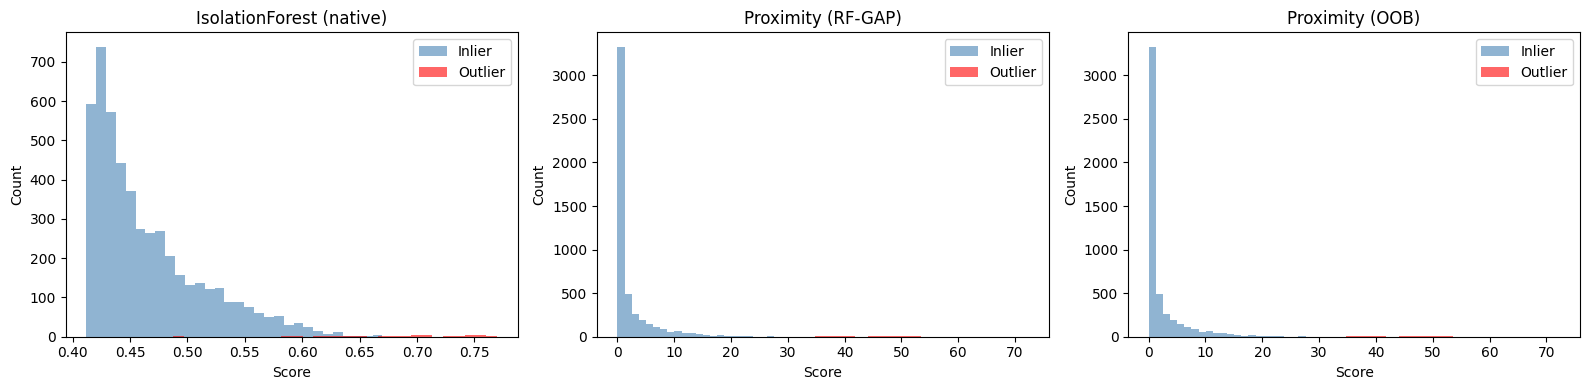

In [383]:
# --- Score distributions: OOB vs RF-GAP ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, scores, title in zip(
    axes,
    [iso_scores, prox_scores, oob_scores],
    ['IsolationForest (native)', 'Proximity (RF-GAP)', 'Proximity (OOB)'],
):
    ax.hist(scores[y_true == 0], bins=30, alpha=0.6, label='Inlier', color='steelblue')
    ax.hist(scores[y_true == 1], bins=30, alpha=0.6, label='Outlier', color='red')
    ax.set_xlabel('Score')
    ax.set_ylabel('Count')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

Method                            ROC-AUC   Avg Precision
---------------------------------------------------------
IsolationForest (native)           0.9924          0.8598
Proximity (RF-GAP)                 0.9914          0.8915
Proximity (OOB)                    0.9914          0.8915


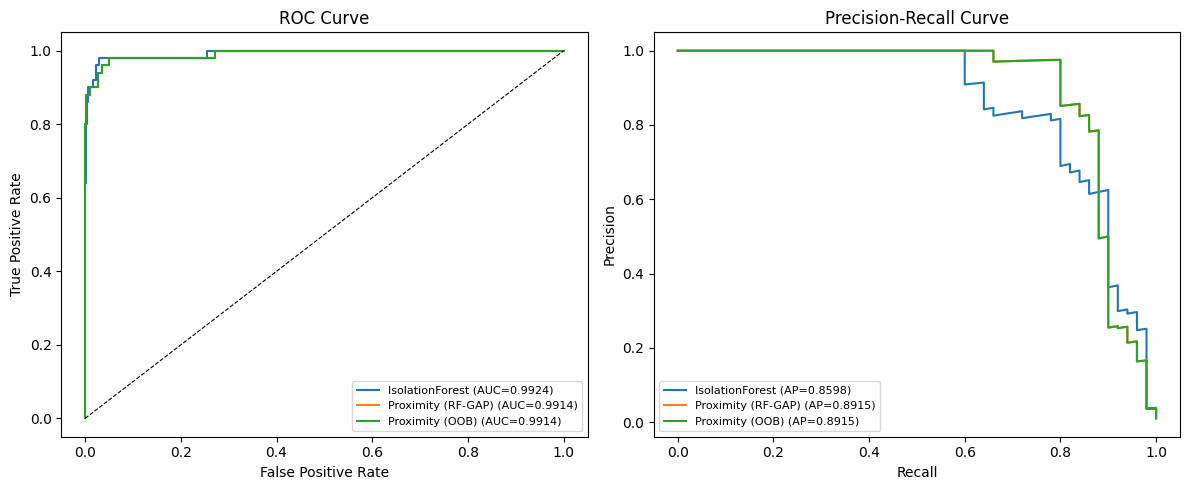

In [384]:
# ROC/PR comparison: IsoForest vs RF-GAP vs OOB
oob_auc = roc_auc_score(y_true, oob_scores)
oob_ap = average_precision_score(y_true, oob_scores)

print(f"{'Method':<30} {'ROC-AUC':>10} {'Avg Precision':>15}")
print('-' * 57)
print(f"{'IsolationForest (native)':<30} {iso_auc:>10.4f} {iso_ap:>15.4f}")
print(f"{'Proximity (RF-GAP)':<30} {prox_auc:>10.4f} {prox_ap:>15.4f}")
print(f"{'Proximity (OOB)':<30} {oob_auc:>10.4f} {oob_ap:>15.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
for scores, label, auc_val in [
    (iso_scores, 'IsolationForest', iso_auc),
    (prox_scores, 'Proximity (RF-GAP)', prox_auc),
    (oob_scores, 'Proximity (OOB)', oob_auc),
]:
    fpr, tpr, _ = roc_curve(y_true, scores)
    ax.plot(fpr, tpr, label=f'{label} (AUC={auc_val:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(fontsize=8)

ax = axes[1]
for scores, label, ap_val in [
    (iso_scores, 'IsolationForest', iso_ap),
    (prox_scores, 'Proximity (RF-GAP)', prox_ap),
    (oob_scores, 'Proximity (OOB)', oob_ap),
]:
    prec, rec, _ = precision_recall_curve(y_true, scores)
    ax.plot(rec, prec, label=f'{label} (AP={ap_val:.4f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 12  Summary

| Metric | IsolationForest (native) | Proximity-based |
|--------|--------------------------|------------------|
| ROC-AUC | see above | see above |
| Avg Precision | see above | see above |
| Spearman rho | — | see section 5 |

**Key takeaways:**

1. Both methods leverage the same IsolationForest model. The native score measures *path length* (isolation difficulty), while the proximity score measures how *dissimilar* a point is to all neighbours in the RF-GAP proximity space.
2. **Apparent IsolationForest "overfitting"** is actually a ground-truth labelling artefact: uniformly sampled outliers that land inside dense clusters are *structurally inliers* — no detector should flag them.
3. **Proximity-based false positives on inliers** reflect real structural information: cluster-edge points with weak proximity connections *are* unusual in the forest's leaf-co-occurrence space, even though they were generated from the inlier distribution.
4. Where both perspectives agree, the flagged anomalies are highly reliable. Where they diverge, the disagreement itself is informative — it separates *isolation-based* anomalousness (path length) from *density-in-proximity-space* anomalousness.

## 13  Anomaly Score Maps — IsolationForest vs ExtendedIsolationForest

Score maps following the style of Figure 2 in [Hariri _et al._ (2019)](https://arxiv.org/abs/1811.02141).
Each panel shows the raw anomaly score evaluated on a fine 2-D grid.

| | Native `score_samples` | Proximity-based (Breiman) |
|---|---|---|
| **IsolationForest** | Top-left | Top-right |
| **ExtendedIsolationForest** | Bottom-left | Bottom-right |

In [385]:
# ---- 2-D data (first two features of the existing standardised data) ----
X_2d_map = X[:, :2]

# ---- Fit both models on 2-D data with OOB proximities ----
ProxIF  = with_sparse_proximity(IsolationForest)
ProxEIF = with_sparse_proximity(ExtendedIsolationForest)

common_kw = dict(
    n_estimators=200,
    contamination=CONTAMINATION,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    prox_method='oob',
)

model_if_2d  = ProxIF(**common_kw)
model_eif_2d = ProxEIF(**common_kw, feature_combinations=X_2d_map.shape[1])
# sktree's EIF hard-codes max_features=1 on the base oblique tree estimator,
# which prevents oblique (multi-feature) splits. Override before fitting.
model_eif_2d.estimator.max_features = X_2d_map.shape[1]

model_if_2d.fit(X_2d_map)
model_eif_2d.fit(X_2d_map)
print("Both 2-D models fitted.")

Both 2-D models fitted.


Grid scores computed.


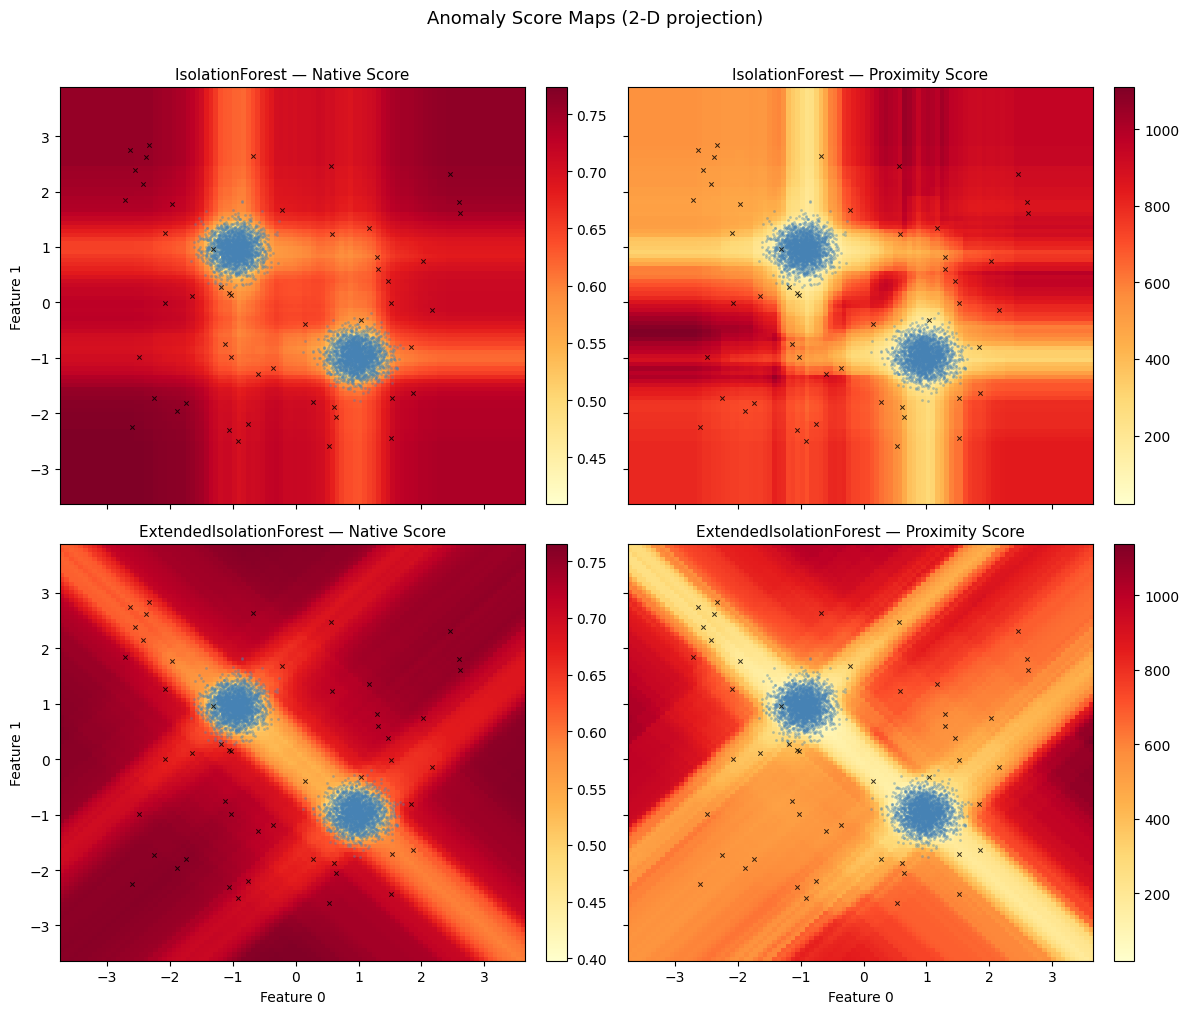

In [386]:
from scipy import sparse as sp_sparse

# ---- Build evaluation grid ----
pad = 1.0
grid_res = 100  # 100 × 100 grid
x_min, x_max = X_2d_map[:, 0].min() - pad, X_2d_map[:, 0].max() + pad
y_min, y_max = X_2d_map[:, 1].min() - pad, X_2d_map[:, 1].max() + pad
xx_map, yy_map = np.meshgrid(
    np.linspace(x_min, x_max, grid_res),
    np.linspace(y_min, y_max, grid_res),
)
grid_pts = np.c_[xx_map.ravel(), yy_map.ravel()]

# ---- Native anomaly scores on grid (negate so higher = more anomalous) ----
Z_if_native  = -model_if_2d.score_samples(grid_pts)
Z_eif_native = -model_eif_2d.score_samples(grid_pts)

# ---- Proximity-based Breiman outlier scores on grid ----
def _prox_grid_scores(mdl, X_grid, n_train):
    """Breiman raw score for new points via prox_extend."""
    P_ext = mdl.prox_extend(X_grid)
    if sp_sparse.issparse(P_ext):
        P_ext_sq = P_ext.copy()
        P_ext_sq.data **= 2
        sum_sq = np.asarray(P_ext_sq.sum(axis=1)).ravel()
    else:
        sum_sq = (P_ext ** 2).sum(axis=1)
    sum_sq = np.maximum(sum_sq, 1e-30)
    return n_train / sum_sq

Z_if_prox  = _prox_grid_scores(model_if_2d,  grid_pts, X_2d_map.shape[0])
Z_eif_prox = _prox_grid_scores(model_eif_2d, grid_pts, X_2d_map.shape[0])
print("Grid scores computed.")

# ---- Plot 2 × 2 score map ----
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

panels = [
    (axes[0, 0], Z_if_native,  "IsolationForest — Native Score"),
    (axes[0, 1], Z_if_prox,    "IsolationForest — Proximity Score"),
    (axes[1, 0], Z_eif_native, "ExtendedIsolationForest — Native Score"),
    (axes[1, 1], Z_eif_prox,   "ExtendedIsolationForest — Proximity Score"),
]

for ax, Z, title in panels:
    Z_grid = Z.reshape(xx_map.shape)
    im = ax.pcolormesh(xx_map, yy_map, Z_grid, cmap="YlOrRd", shading="auto")
    ax.scatter(X_2d_map[y_true == 0, 0], X_2d_map[y_true == 0, 1],
               c="steelblue", s=4, alpha=0.4, linewidths=0)
    ax.scatter(X_2d_map[y_true == 1, 0], X_2d_map[y_true == 1, 1],
               c="black", s=10, alpha=0.8, marker="x", linewidths=0.7)
    ax.set_title(title, fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[1, 0].set_xlabel("Feature 0")
axes[1, 1].set_xlabel("Feature 0")
axes[0, 0].set_ylabel("Feature 1")
axes[1, 0].set_ylabel("Feature 1")
fig.suptitle("Anomaly Score Maps (2-D projection)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [387]:
# ---- Verify EIF is using oblique splits ----
eif_tree0 = model_eif_2d.estimators_[0]
proj = eif_tree0.tree_.get_projection_matrix()
internal = (eif_tree0.tree_.feature != -2)
n_oblique = sum(np.count_nonzero(proj[i]) > 1 for i in range(proj.shape[0]) if internal[i])
n_total = internal.sum()
print(f"EIF tree 0: {n_oblique}/{n_total} internal nodes use oblique (multi-feature) splits")
print(f"Sample projections: {proj[internal][:5].tolist()}")

EIF tree 0: 67/67 internal nodes use oblique (multi-feature) splits
Sample projections: [[1.0, 1.0], [1.0, 1.0], [1.0, 1.0], [-1.0, 1.0], [1.0, 1.0]]
